![Banner](../images/09_12_surface_energy_balance_modeling.png)

# SEBAL: Solving for Sensible Heat with Hot and Cold Pixels

SEBAL, the Surface Energy Balance Algorithm for Land (Bastiaanssen et al. 1998), was the first
energy balance model designed to run on a single satellite image with almost no ground data. Its
central idea is to let the image calibrate itself. Somewhere in the scene there is a field so wet
that all its available energy goes into evaporation, and somewhere a field so dry that none does.
Between them, the near-surface temperature difference that drives sensible heat is assumed to
change linearly with surface temperature. This notebook selects the two anchor pixels by hand and
with the automated percentile method, runs the calibration and the stability iteration step by
step, maps sensible heat, latent heat and the evaporative fraction, scales them to daily ET, and
checks how much the result depends on the choice of anchors.

## Overview

### The SEBAL assumptions

1. **Linear dT.** The temperature difference `dT` between 0.1 and 2 m above the surface is a linear
   function of LST: `dT = a + b Ts`. This replaces an unknown air temperature at every pixel with
   two numbers for the whole scene.
2. **Hot anchor.** At a dry, bare pixel there is no evaporation: `LE_hot = 0`, so
   `H_hot = Rn - G` and `dT_hot = H_hot rah_hot / (rho cp)`.
3. **Cold anchor.** At a wet, well vegetated pixel all available energy evaporates: `H_cold = 0`,
   so `dT_cold = 0`.
4. **Constant evaporative fraction.** `EF = LE / (Rn - G)` at the overpass holds for the whole day,
   so daily ET is `EF Rn24` converted to mm, with `Rn24` the 24 hour mean net radiation.

With the two anchors, `b = (dT_hot - dT_cold) / (Ts_hot - Ts_cold)` and `a = dT_hot - b Ts_hot`.

### Why the iteration

`rah` depends on stability, stability on `H`, and `H` on `dT`, which depends on `rah` at the hot
pixel. SEBAL starts neutral, computes `a`, `b` and `H` for every pixel, updates the Monin-Obukhov
length and the corrections, recomputes `rah` and the anchor `dT`, and repeats until `rah` at the
hot pixel stops changing (usually 5 to 10 iterations).

### Why it works, and where it does not

The linear `dT` assumption is reasonable because both `Ts` and the near-surface air temperature
are pulled up by the same thing, sensible heat. Because the calibration is internal, biases in LST
(from atmospheric correction or emissivity) and in roughness are largely absorbed: what matters is
the contrast between pixels, not their absolute temperature. The two anchor assumptions are the
weak points:

- In arid, advective regions such as the San Joaquin Valley in summer, well watered fields can
  evaporate more than `Rn - G` by drawing heat from the air (`H < 0`). Setting `H_cold = 0` then
  underestimates ET of the wettest fields; METRIC (notebook 06) addresses this.
- After rain a bare field still evaporates, so `LE_hot = 0` overestimates `H` across the image.
- The anchors must be representative: large, uniform fields, away from cloud edges, at similar
  elevation.

### Automated anchor selection

Allen et al. (2013) automated anchor selection for METRIC with percentile rules, refined in
eeMETRIC and geeSEBAL:

| Anchor | Pool | Then |
|---|---|---|
| cold | NDVI in the top 5 % of the image, albedo between 0.18 and 0.25 | the coolest 20 % of that pool |
| hot | NDVI in the bottom 10 %, between 0.10 and 0.28 (bare soil, not water) | the hottest 20 % of that pool |

From each pool GeoLattice keeps the candidates whose local LST standard deviation (3 x 3 pixels) is
at or below the pool median, which removes field edges, and picks the pixel whose LST is closest
to the pool mean. A land cover screen (for example, alfalfa for the cold pool and fallow for the
hot pool) can narrow the pools further.

## SEBAL with GeoLattice

| Function | Purpose |
|---|---|
| `seb.candidate_anchors`, `seb.select_anchors`, `seb.anchor_at`, `seb.anchor_report` | anchor pools, automated and manual selection |
| `seb.calibrate_dt` | `a` and `b` from the anchors |
| `seb.sensible_heat_iterative` | `H` with the stability iteration |
| `seb.run_sebal` | the whole model: `H`, `LE`, `EF`, instantaneous and daily ET |
| `seb.calibration_history` | the iteration table of a run |
| `seb.daily_net_radiation` | `Rn24` for the daily scaling |
| `seb.monte_carlo_anchors` | spread of the result over many anchor pairs |

### Learning objectives

1. State the four SEBAL assumptions and derive `a` and `b` from the anchors.
2. Select hot and cold anchors by hand and with the percentile method, and judge whether they are
   representative.
3. Follow the stability iteration until the hot pixel's `rah` converges.
4. Map `H`, `LE`, the evaporative fraction and daily ET.
5. Check the anchor constraints and find pixels where the assumptions break.
6. Quantify how much daily ET depends on the choice of anchors.

### Data

The 5 July 2024 Landsat 8 scene of the Westside San Joaquin Valley (`sd.load_scene`) with the
net radiation, soil heat flux and roughness of notebooks 03 and 04 (`sd.energy_inputs`) and the
ERA5 daily shortwave for `Rn24`.

### Contents

- Setup
- Anchor candidates
- Choosing the anchors
- One calibration step by hand
- The stability iteration
- Sensible heat, latent heat and evaporative fraction
- Daily ET
- Checking the assumptions
- How much do the anchors matter?
- Summary and exercises

## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import rioxarray  # noqa: F401  (registers the .rio accessor)
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.rsense.surface_energy_balance as seb  # energy balance and ET models
import seb_data as sd  # chapter helper: downloads, caches and loads the scenes

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
OUT = Path("outputs")  # results written by this chapter
OUT.mkdir(exist_ok=True)  # create it if needed
print("GeoLattice", geolattice.__version__, "| data folder", sd.DATA.relative_to(sd.DATA.parents[3]))  # versions and paths

ds = sd.load_scene()  # Landsat 8, 5 July 2024
p = sd.energy_inputs(ds)  # radiation, soil heat flux, roughness, wind at 200 m
ext = [float(ds.x.min()), float(ds.x.max()), float(ds.y.min()), float(ds.y.max())]  # map extent
GROUPS = {"Tree crops": [75, 204, 76, 211, 212, 217], "Grapes": [69], "Annual crops": [54, 2, 1, 36, 208, 24, 21, 51],
          "Fallow": [61], "Grass and shrubs": [176, 152], "Developed": [121, 122, 123, 124]}  # CDL codes per group


def by_group(**layers):  # mean of each layer per crop group
    df = xr.Dataset(layers).assign(cdl=ds.cdl).to_dataframe().dropna()  # one row per pixel
    return pd.DataFrame({g: df[df.cdl.isin(c)].drop(columns=["cdl", "spatial_ref"], errors="ignore").mean()
                         for g, c in GROUPS.items()}).T  # group means

GeoLattice 0.3.49 | data folder GeoLattice/Data/08_remote_sensing/08_12_surface_energy_balance


## Anchor candidates

`seb.candidate_anchors` applies the percentile rules and returns two boolean maps.

In [2]:
usable = p["mask"] & (ds.water == 0)  # clear land
cand = seb.candidate_anchors(p["ndvi"], p["lst"], albedo_=p["albedo"], mask=usable)  # percentile pools
print(f"cold pool: {int(cand['cold'].sum())} pixels | hot pool: {int(cand['hot'].sum())} pixels")  # pool sizes
pools = pd.DataFrame({k: {"pixels": int(v.sum()), "NDVI": float(p["ndvi"].where(v).mean()),
                          "LST (C)": float(p["lst"].where(v).mean()) - 273.15, "albedo": float(p["albedo"].where(v).mean())}
                      for k, v in cand.items()}).T  # pool summary
pools["main crops"] = [", ".join(sd.cdl_name(c) for c in ds.cdl.where(v).to_series().value_counts().index[:3]) for v in cand.values()]  # crops in each pool
pools.round(3)  # table

cold pool: 3636 pixels | hot pool: 11899 pixels


,pixels,NDVI,LST (C),albedo,main crops
cold,3636.0,0.858,35.277,0.211,"Corn, Almonds, Tomatoes"
hot,11899.0,0.106,60.073,0.187,"Fallow/idle cropland, Other hay, Herbs"


## Choosing the anchors

`seb.select_anchors` picks one pixel from each pool. For comparison, a manual pair is chosen the way
an analyst would look for extremes: the coolest dense pixel (NDVI above 0.8) and the hottest fallow
pixel, each inside a 7 x 7 pixel (210 m) window whose LST varies by less than 0.4 K, at least 300 m
from the image edge.

In [3]:
auto = seb.select_anchors(p["ndvi"], p["lst"], albedo_=p["albedo"], candidates=cand)  # automated: closest to pool mean, homogeneous
ndvi_v, lst_v = p["ndvi"].values, p["lst"].values  # arrays
from scipy import ndimage  # local filters

f = np.nan_to_num(lst_v, nan=400.0)  # LST with gaps filled by an impossible value
sd7 = np.sqrt(np.maximum(ndimage.uniform_filter(f ** 2, 7) - ndimage.uniform_filter(f, 7) ** 2, 0))  # LST standard deviation in 7 x 7 windows
uniform = sd7 < 0.4  # LST nearly uniform over 210 m
uniform[:10] = uniform[-10:] = False; uniform[:, :10] = uniform[:, -10:] = False  # stay 300 m away from the image edge
cold_i = np.nanargmin(np.where(uniform & (ndvi_v > 0.8), lst_v, np.nan))  # coolest uniform dense pixel
hot_i = np.nanargmax(np.where(uniform & (ndvi_v < 0.2) & (ndvi_v > 0.1) & ds.cdl.isin([61]).values, lst_v, np.nan))  # hottest uniform fallow pixel
manual = {k: seb.anchor_at(p["ndvi"], float(ds.x[i % ds.sizes["x"]]), float(ds.y[i // ds.sizes["x"]]),
                           ndvi=p["ndvi"], lst=p["lst"], albedo=p["albedo"]) for k, i in [("cold", cold_i), ("hot", hot_i)]}  # anchor records
tab = pd.concat({"automated": seb.anchor_report(auto, rn=p["rn"], g=p["g"]),
                 "manual": seb.anchor_report(manual, rn=p["rn"], g=p["g"])})  # both pairs
tab["crop"] = [sd.cdl_name(ds.cdl.values[r.iy, r.ix]) for r in tab.itertuples()]  # crop of each anchor
tab["lst_c"] = tab.lst - 273.15  # C
tab[["iy", "ix", "ndvi", "lst_c", "albedo", "rn", "g", "crop"]].round(3)  # table

iy   ix   ndvi   lst_c  albedo       rn        g  \
          anchor                                                      
automated cold    193   25  0.832  35.236   0.191  641.937   37.169   
          hot     206  193  0.109  60.037   0.185  475.293  147.991   
manual    cold     21  626  0.881  33.024   0.266  585.376   33.894   
          hot      12  235  0.171  63.373   0.194  439.275  150.970   

                                  crop  
          anchor                        
automated cold                 Almonds  
          hot                Other hay  
manual    cold                Tomatoes  
          hot     Fallow/idle cropland

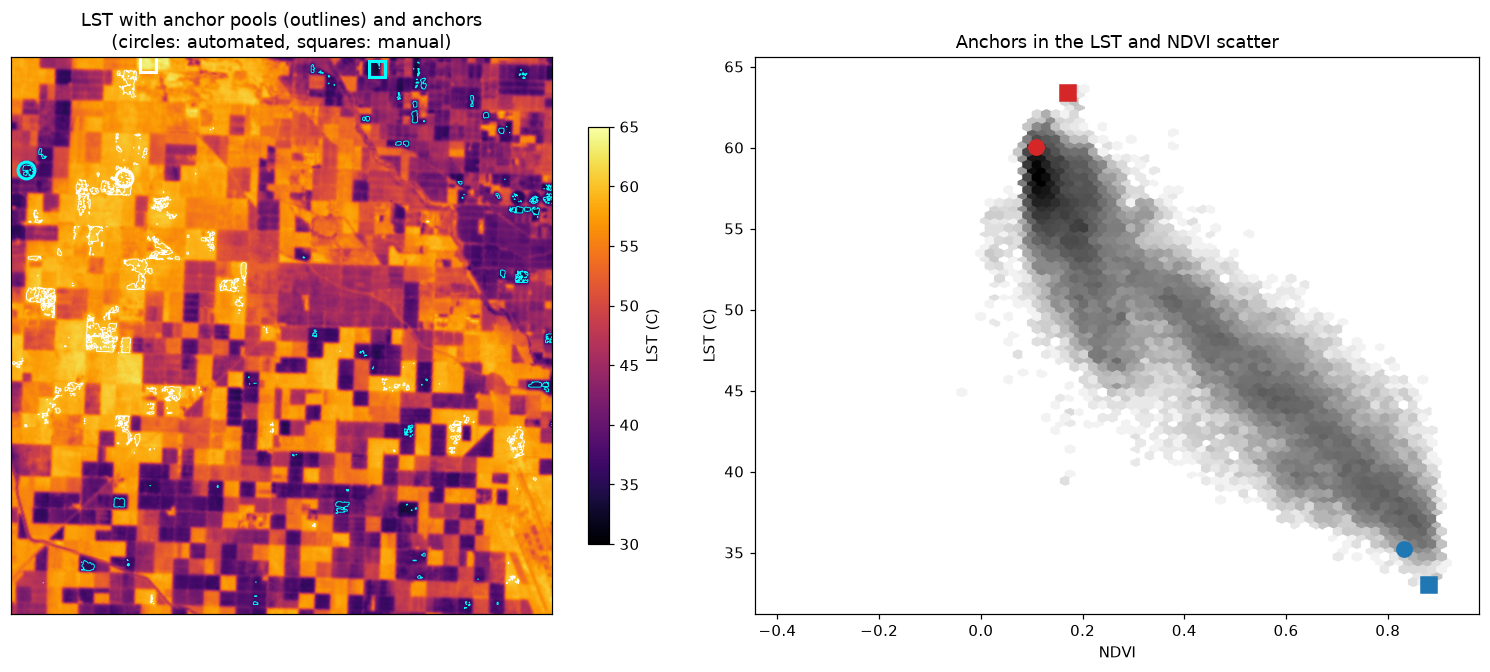

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(14, 6))  # two maps
im = ax[0].imshow(p["lst"] - 273.15, extent=ext, cmap="inferno", vmin=30, vmax=65); plt.colorbar(im, ax=ax[0], shrink=0.75, label="LST (C)")  # LST
ax[0].contour(ds.x, ds.y, cand["cold"].astype(int), levels=[0.5], colors="cyan", linewidths=0.6)  # cold pool outline
ax[0].contour(ds.x, ds.y, cand["hot"].astype(int), levels=[0.5], colors="white", linewidths=0.6)  # hot pool outline
for rec, mk in [(auto, "o"), (manual, "s")]:  # automated and manual anchors
    for k, c in [("cold", "cyan"), ("hot", "white")]:  # both anchors
        ax[0].plot(rec[k]["x"], rec[k]["y"], mk, ms=11, mfc="none", mec=c, mew=2)  # marker
ax[0].set_title("LST with anchor pools (outlines) and anchors\n(circles: automated, squares: manual)"); ax[0].set_xticks([]); ax[0].set_yticks([])  # title
s = pd.DataFrame({"ndvi": ndvi_v.ravel(), "lst": lst_v.ravel() - 273.15}).dropna().sample(60000, random_state=0)  # sample of pixels
ax[1].hexbin(s.ndvi, s.lst, gridsize=70, bins="log", cmap="Greys")  # scatter density
for rec, mk in [(auto, "o"), (manual, "s")]:  # anchors on the scatter
    ax[1].plot(rec["cold"]["ndvi"], rec["cold"]["lst"] - 273.15, mk, ms=10, color="tab:blue")  # cold
    ax[1].plot(rec["hot"]["ndvi"], rec["hot"]["lst"] - 273.15, mk, ms=10, color="tab:red")  # hot
ax[1].set_xlabel("NDVI"); ax[1].set_ylabel("LST (C)"); ax[1].set_title("Anchors in the LST and NDVI scatter")  # labels
plt.tight_layout(); plt.show()  # draw

Both pairs sit in the expected corners of the scatter; the manual pair, chosen as extremes, lies
just outside the main cloud of pixels (a tomato field at 33 C and a fallow field at 63 C). The
automated cold anchor is not the very
coolest pixel but a typical member of the coolest, densest pool, which is the intent: a single
extreme pixel may be a wet spot, a canal or a cloud remnant. The automated run is used from here
on; the last section measures how much this choice matters.

## One calibration step by hand

The first SEBAL step assumes neutral air. With the hot and cold anchors:

In [5]:
hot, cold = auto["hot"], auto["cold"]  # the automated anchors
hy, hx, cy, cx = hot["iy"], hot["ix"], cold["iy"], cold["ix"]  # their rows and columns
u200, P = p["u200"], p["pressure"]  # wind at 200 m, pressure map
ustar = seb.friction_velocity(u200, 200.0, p["zom"])  # neutral u*
rah0 = seb.aerodynamic_resistance(ustar)  # neutral rah between 0.1 and 2 m
H_hot = float(p["rn"][hy, hx] - p["g"][hy, hx])  # LE = 0 at the hot pixel
rho_hot = float(seb.air_density(float(P[hy, hx]), hot["lst"]))  # a first guess of air density
dT_hot = H_hot * float(rah0[hy, hx]) / (rho_hot * seb.CP)  # K
a0, b0 = seb.calibrate_dt(hot["lst"], cold["lst"], dT_hot, 0.0)  # dT = a + b Ts with dT_cold = 0
print(f"hot pixel: Rn - G = {H_hot:.0f} W/m2, neutral rah = {float(rah0[hy, hx]):.1f} s/m, dT_hot = {dT_hot:.2f} K")  # hot anchor
print(f"dT = {a0:.2f} + {b0:.4f} Ts   (dT = 0 at Ts = {cold['lst'] - 273.15:.1f} C)")  # the line

hot pixel: Rn - G = 327 W/m2, neutral rah = 60.5 s/m, dT_hot = 18.94 K
dT = -235.50 + 0.7636 Ts   (dT = 0 at Ts = 35.2 C)


With neutral resistance the hot pixel needs a `dT` of about 19 K to carry all its available energy
as sensible heat. That is too large: hot, dry surfaces are strongly unstable, so their real `rah`
is much smaller and a smaller `dT` suffices. The iteration finds it.

## The stability iteration

`seb.sensible_heat_iterative` repeats the step above with stability corrections until the hot
pixel's `rah` changes by less than 0.5 %. SEBAL's anchor rules are the defaults (`le_hot=None`
means 0, `le_cold=None` means `H_cold = 0`).

converged: True after 5 iterations | final dT = -65.80 + 0.2134 Ts


,rah_hot,rah_cold,u_star_hot,dt_hot,dt_cold,a,b,h_hot,L_hot
iteration,,,,,,,,,
1,60.502,42.958,0.121,18.005,0.0,-223.878,0.726,328.931,-0.490
2,13.170,42.958,0.150,3.900,0.0,-48.493,0.157,313.282,-0.945
3,17.455,42.958,0.150,5.400,0.0,-67.146,0.218,328.800,-0.905
4,17.144,42.958,0.150,5.280,0.0,-65.647,0.213,327.182,-0.909
5,17.176,42.958,0.150,5.291,0.0,-65.795,0.213,327.314,-0.909


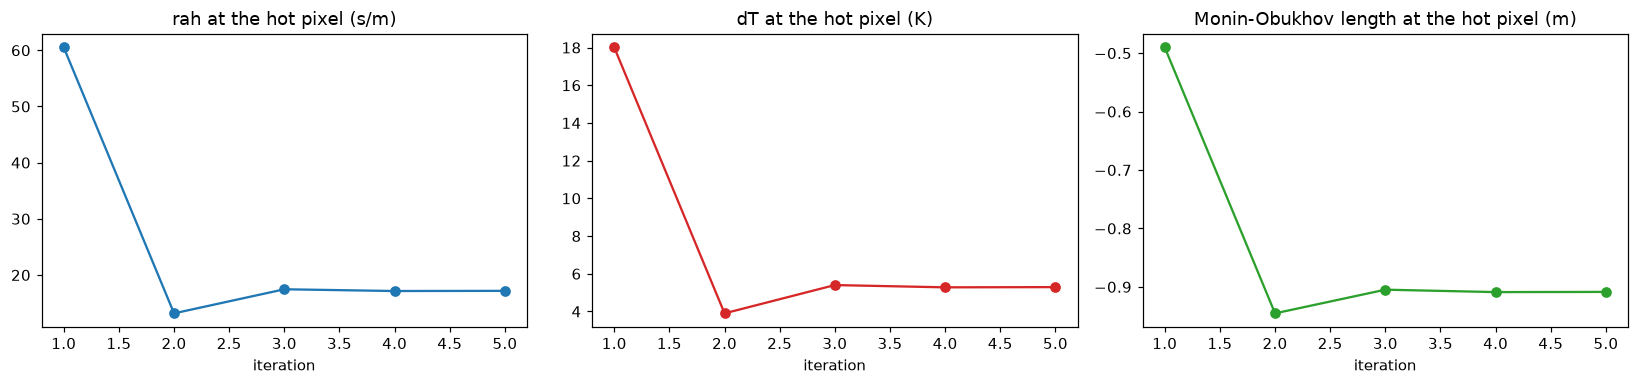

In [6]:
sh = seb.sensible_heat_iterative(p["lst"], p["rn"], p["g"], p["zom"], u200, P, auto)  # SEBAL calibration
hist = sh["history"]  # one row per iteration
print(f"converged: {sh['converged']} after {sh['iterations']} iterations | final dT = {sh['a']:.2f} + {sh['b']:.4f} Ts")  # result
display(hist.round(3))  # the iterations
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))  # three panels
ax[0].plot(hist.index, hist.rah_hot, "o-"); ax[0].set_title("rah at the hot pixel (s/m)")  # resistance
ax[1].plot(hist.index, hist.dt_hot, "o-", color="tab:red"); ax[1].set_title("dT at the hot pixel (K)")  # temperature difference
ax[2].plot(hist.index, hist.L_hot, "o-", color="tab:green"); ax[2].set_title("Monin-Obukhov length at the hot pixel (m)")  # stability
for a in ax:  # every panel
    a.set_xlabel("iteration")  # x label
plt.tight_layout(); plt.show()  # draw

In the first iterations `rah` at the hot pixel drops sharply as the strongly unstable air (a
Monin-Obukhov length of about -1 m) is taken into account, and `dT_hot` falls with it. The
iteration then settles within a few steps. Throughout, `H` at the hot pixel stays equal to its
`Rn - G`: the calibration enforces it.

## Sensible heat, latent heat and evaporative fraction

`seb.run_sebal` wraps the calibration and returns a Dataset.

Rs24 343 W/m2, tau24 0.72, Rn24 median 195 W/m2


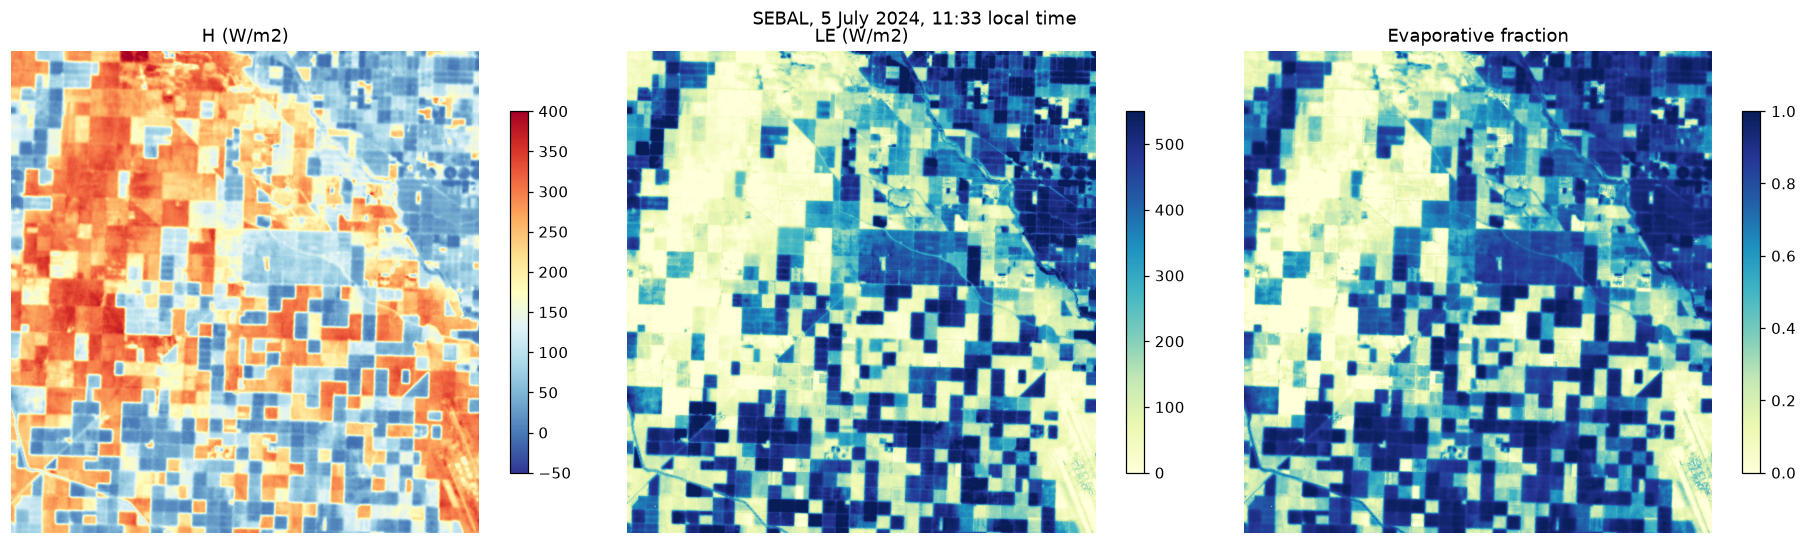

,Rn,G,H,LE,EF
Tree crops,566.38,99.20,129.80,337.38,0.68
Grapes,554.06,68.65,82.78,402.64,0.82
Annual crops,519.13,87.61,126.67,304.85,0.63
Fallow,484.50,144.02,278.30,62.18,0.18
Grass and shrubs,478.40,138.95,245.13,94.32,0.27
Developed,501.42,133.34,204.27,163.81,0.41


In [7]:
rs24 = ds.attrs["rs_daily_mj"] * 1e6 / 86400  # 24 h mean shortwave from ERA5, W/m2
ra24 = float(seb.extraterrestrial_radiation_daily(sd.WESTSIDE["lat"], ds.attrs["doy"])) * 1e6 / 86400  # W/m2
rn24 = seb.daily_net_radiation(rs24, p["albedo"], ra24=ra24)  # 24 h mean net radiation, W/m2
res = seb.run_sebal(p["lst"], p["rn"], p["g"], p["zom"], u200, P, anchors=auto, rn24=rn24)  # SEBAL
print(f"Rs24 {rs24:.0f} W/m2, tau24 {rs24 / ra24:.2f}, Rn24 median {float(rn24.median()):.0f} W/m2")  # daily radiation
fig, ax = plt.subplots(1, 3, figsize=(17, 5))  # three maps
for a, v, cm, lim, t in [(ax[0], res.h, "RdYlBu_r", (-50, 400), "H (W/m2)"), (ax[1], res.le, "YlGnBu", (0, 550), "LE (W/m2)"),
                         (ax[2], res.ef, "YlGnBu", (0, 1), "Evaporative fraction")]:  # three layers
    im = a.imshow(v, extent=ext, cmap=cm, vmin=lim[0], vmax=lim[1]); plt.colorbar(im, ax=a, shrink=0.75); a.set_title(t); a.axis("off")  # map
plt.suptitle("SEBAL, 5 July 2024, 11:33 local time"); plt.tight_layout(); plt.show()  # draw
by_group(Rn=p["rn"], G=p["g"], H=res.h, LE=res.le, EF=res.ef).round(2)  # per crop group

Sensible heat is the mirror image of LST: near zero over the cool crops, around `Rn - G` over the
hot fallow land. LE and EF follow the irrigated fields. Because the cold anchor is forced to
`H = 0` and EF is clipped at 1, no pixel can draw heat from the air here, which matters on a day
like this (see the last section and notebook 06).

## Daily ET

SEBAL keeps EF constant for the day: `ET24 = 86400 EF Rn24 / lambda`.

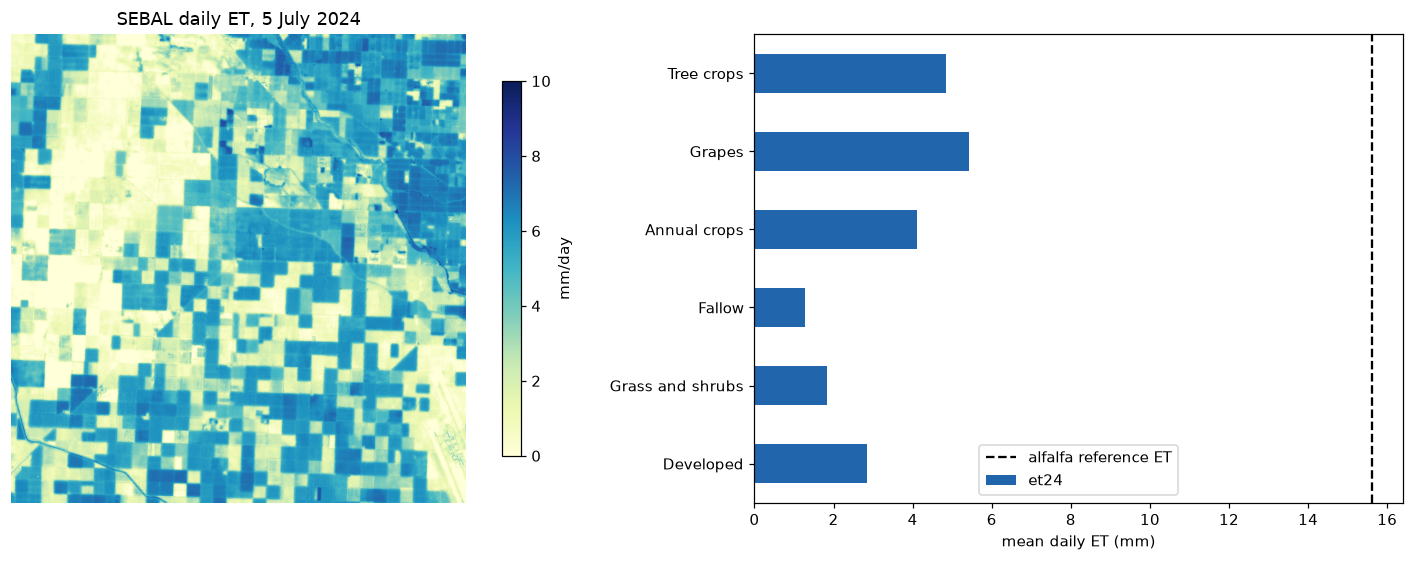

,et24,et_inst
Tree crops,4.85,0.51
Grapes,5.43,0.60
Annual crops,4.12,0.46
Fallow,1.27,0.09
Grass and shrubs,1.82,0.14
Developed,2.84,0.25


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.1, 1]})  # map and bars
im = ax[0].imshow(res.et24, extent=ext, cmap="YlGnBu", vmin=0, vmax=10); plt.colorbar(im, ax=ax[0], shrink=0.8, label="mm/day")  # daily ET
ax[0].set_title("SEBAL daily ET, 5 July 2024"); ax[0].axis("off")  # title
grp = by_group(et24=res.et24, et_inst=res.et_inst)  # per crop group
grp.et24.plot.barh(ax=ax[1], color="#2166ac"); ax[1].set_xlabel("mean daily ET (mm)"); ax[1].invert_yaxis()  # bars
ax[1].axvline(sd.reference_et(ds)["etr_daily"], color="k", ls="--", label="alfalfa reference ET"); ax[1].legend()  # reference
plt.tight_layout(); plt.show()  # draw
grp.round(2)  # table

SEBAL's daily ET for the irrigated crops (about 4 to 5.5 mm on average) is far below the alfalfa
reference ET of the day (15.6 mm), even though several of these fields are close to full cover and
well watered. The 24 hour net radiation is only about 195 W m-2, a third of the instantaneous
value. Two SEBAL
assumptions combine here: the cold anchor cannot evaporate more than `Rn - G`, and the daily
scaling uses `Rn24`, which on a hot, dry, advective day is much smaller than the energy the crops
actually use. The next notebook replaces both with the reference ET.

## Checking the assumptions

In [9]:
checks = {"H at the cold anchor (W/m2)": float(res.h[cy, cx]),  # should be 0
          "LE at the hot anchor (W/m2)": float(res.le[hy, hx]),  # should be 0
          "pixels with LE < 0 (%)": 100 * float((res.le < 0).sum() / res.le.notnull().sum()),  # drier than the hot anchor
          "pixels with LE > Rn - G before clipping (%)": 100 * float(((res.le / (p["rn"] - p["g"])) > 1).sum() / res.le.notnull().sum()),  # cooler than the cold anchor
          "pixels hotter than the hot anchor (%)": 100 * float((p["lst"] > hot["lst"]).sum() / p["lst"].notnull().sum()),  # outside the line
          "pixels cooler than the cold anchor (%)": 100 * float((p["lst"] < cold["lst"]).sum() / p["lst"].notnull().sum())}  # outside the line
pd.Series(checks).round(2).to_frame("value")  # table

,value
H at the cold anchor (W/m2),0.00
LE at the hot anchor (W/m2),-0.01
pixels with LE < 0 (%),6.51
pixels with LE > Rn - G before clipping (%),0.54
pixels hotter than the hot anchor (%),2.25
pixels cooler than the cold anchor (%),0.54


The calibration constraints hold at the anchors. Some pixels lie beyond each anchor: 2.3 % are
hotter than the hot anchor and 6.5 % get negative LE (hot pixels with less available energy than
the anchor), while 0.5 % are cooler than the cold anchor and get LE above `Rn - G`. Both are expected when the anchors are typical members of their pools rather than
the extremes; models clip EF to 0 to 1 (SEBAL) or ETrF to a range (METRIC) for daily ET.

## How much do the anchors matter?

`seb.monte_carlo_anchors` reruns the model for many anchor pairs drawn at random from the pools
and stacks the results. Ten draws give a first impression; notebook 11 does a fuller analysis.

In [10]:
def run(anchors):  # SEBAL daily ET for one anchor pair
    return seb.run_sebal(p["lst"], p["rn"], p["g"], p["zom"], u200, P, anchors=anchors, rn24=rn24).et24  # mm/day


stack, used = seb.monte_carlo_anchors(run, cand, n=10, seed=1)  # ten random anchor pairs
means = stack.mean(["y", "x"]).values  # scene mean ET of each draw
print(f"scene mean daily ET over 10 anchor pairs: {means.mean():.2f} mm, range {means.min():.2f} to {means.max():.2f} mm")  # spread of the mean
spread = stack.std("draw")  # per-pixel standard deviation
by_group(et24_mean=stack.mean("draw"), et24_sd=spread).round(2)  # per crop group

scene mean daily ET over 10 anchor pairs: 3.67 mm, range 3.38 to 4.16 mm


,et24_mean,et24_sd
Tree crops,4.90,0.16
Grapes,5.46,0.11
Annual crops,4.16,0.16
Fallow,1.36,0.33
Grass and shrubs,1.90,0.27
Developed,2.90,0.25


Different but equally reasonable anchors from the same pools moved the scene mean daily ET between
3.4 and 4.2 mm, and the per-pixel standard deviation (0.1 to 0.3 mm) is small compared with the
differences between crops, largest over fallow land, which sits near the hot pool. The automated pools are tight enough here because the scene has a
clear contrast between irrigated and fallow land. In scenes without large dry fields, or after
rain, the hot pool widens and the spread grows.

## Summary and exercises

- SEBAL calibrates `dT = a + b Ts` with a hot anchor (`LE = 0`) and a cold anchor (`H = 0`), and
  iterates `rah` and stability until the hot pixel converges.
- The automated percentile pools found an orchard and a hay stubble field as anchors; a manual pair
  in large uniform fields gives similar values.
- At the hot pixel, the stability iteration lowered `rah` from 60.5 s/m (neutral) to 17.2 s/m in
  five iterations, and `dT_hot` from about 19 K to 5.3 K.
- SEBAL maps `H`, `LE` and EF well, but on this hot, advective day its daily ET for irrigated crops
  stays far below the alfalfa reference ET, because `H_cold = 0` and the `Rn24` scaling cannot
  represent energy drawn from the air.
- Ten random anchor pairs from the pools moved the scene mean daily ET between 3.4 and 4.2 mm.

**Exercises**

1. Restrict the cold pool to alfalfa (`cold_classes=[36]`) and the hot pool to fallow
   (`hot_classes=[61]`). How do the anchors and the daily ET change?
2. Run SEBAL on the 8 April 2024 scene. Is the contrast between the anchors larger or smaller than
   in July, and what does that do to the iteration?
3. Replace the METRIC soil heat flux with the SEBAL formula (`method="bastiaanssen"`) and rerun.
   Which crops change most?
4. Use `seb.anchor_at` to put the hot anchor in a developed (urban) pixel. What happens to `b`, and
   why is that a poor choice?